<a href="https://colab.research.google.com/github/Bhuvibagga/VDUI-UNIT3-PES2UG24CS117/blob/ppt7/unit3_ppt7_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

Dataset loaded: (5520, 11)
Columns: ['txn_id', 'timestamp', 'day', 'hour', 'customer_id', 'city', 'merchant_category', 'amount_inr', 'distance_from_home_km', 'detector_score', 'is_fraud']


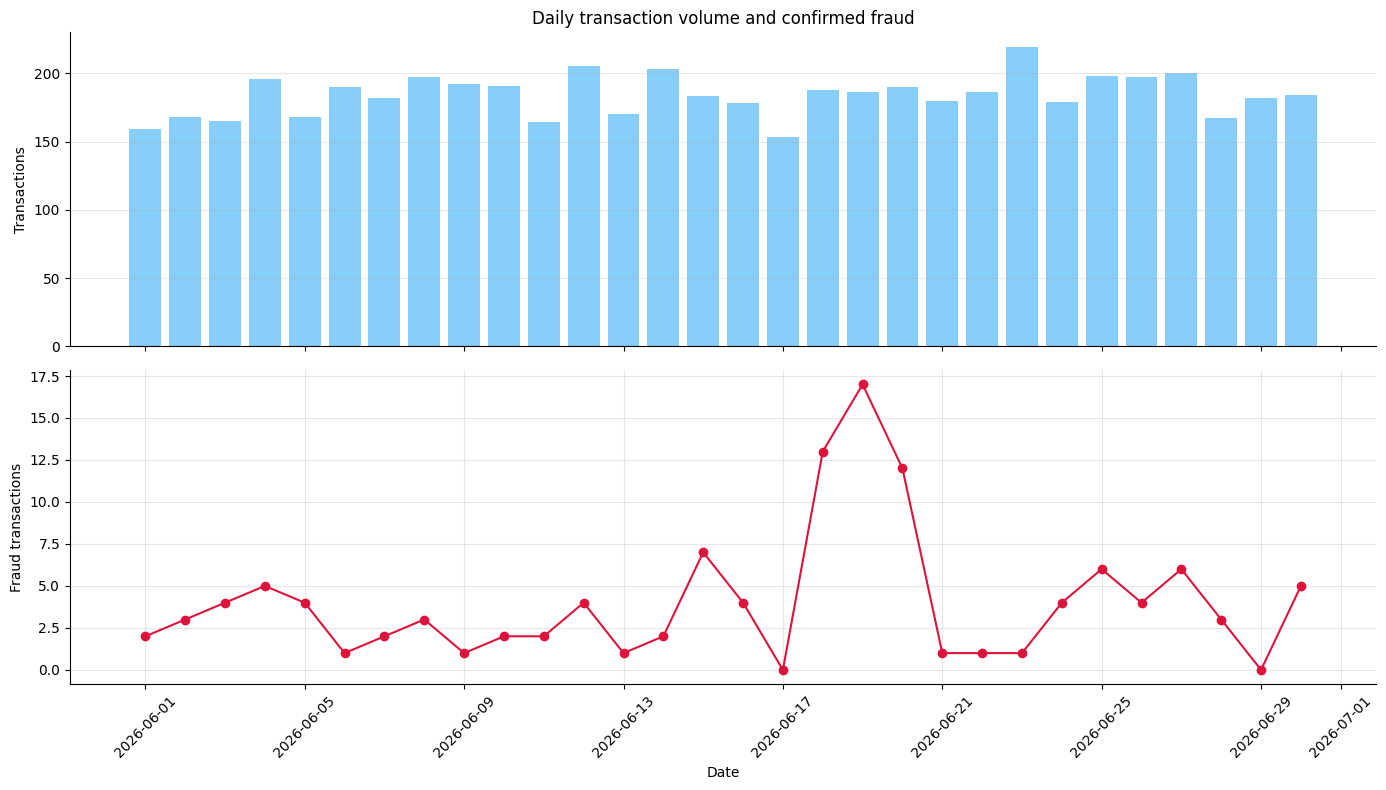

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the dataset
file_path = Path("/content/unit3_ppt7_card_transactions.csv")

if not file_path.exists():
    from google.colab import files
    uploaded = files.upload()
    file_path = Path(next(iter(uploaded)))

df = pd.read_csv(file_path)

# Check and standardize column names
df.columns = df.columns.str.strip()

print("Dataset loaded:", df.shape)
print("Columns:", df.columns.tolist())

# Identify the date column
date_col = next(
    (c for c in df.columns if c.lower() in ["date", "transaction_date", "timestamp", "transaction_time"]),
    None
)

# Identify the transaction ID column
id_col = next(
    (c for c in df.columns if c.lower() in ["transaction_id", "transactionid", "id"]),
    None
)

# Identify the fraud indicator column
fraud_col = next(
    (c for c in df.columns if c.lower() in ["is_fraud", "fraud", "fraud_flag", "isfraud"]),
    None
)

if date_col is None or fraud_col is None:
    raise ValueError(
        "Could not identify date/fraud columns. "
        "Check the printed column names and adjust date_col and fraud_col."
    )

# Convert dates and fraud indicators
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df[fraud_col] = pd.to_numeric(df[fraud_col], errors="coerce")

df = df.dropna(subset=[date_col, fraud_col]).copy()
df["day"] = df[date_col].dt.floor("D")

# Daily transaction volume and confirmed fraud
daily = df.groupby("day").agg(
    transactions=(fraud_col, "size"),
    fraud=(fraud_col, "sum")
)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].bar(daily.index, daily["transactions"], color="lightskyblue")
axes[0].set_ylabel("Transactions")
axes[0].set_title("Daily transaction volume and confirmed fraud")
axes[0].grid(axis="y", alpha=0.3)

axes[1].plot(daily.index, daily["fraud"], color="crimson", marker="o")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Fraud transactions")
axes[1].grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The overview reveals changes in total transaction volume over time and whether confirmed fraud clusters on particular days or in particular cities. A score-sorted alert list shows individual high-scoring transactions, but can hide broader temporal and geographic patterns. The relevant concept is overview first (Shneiderman’s mantra) followed by a reordered matrix / visual pattern discovery (Slide 39).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

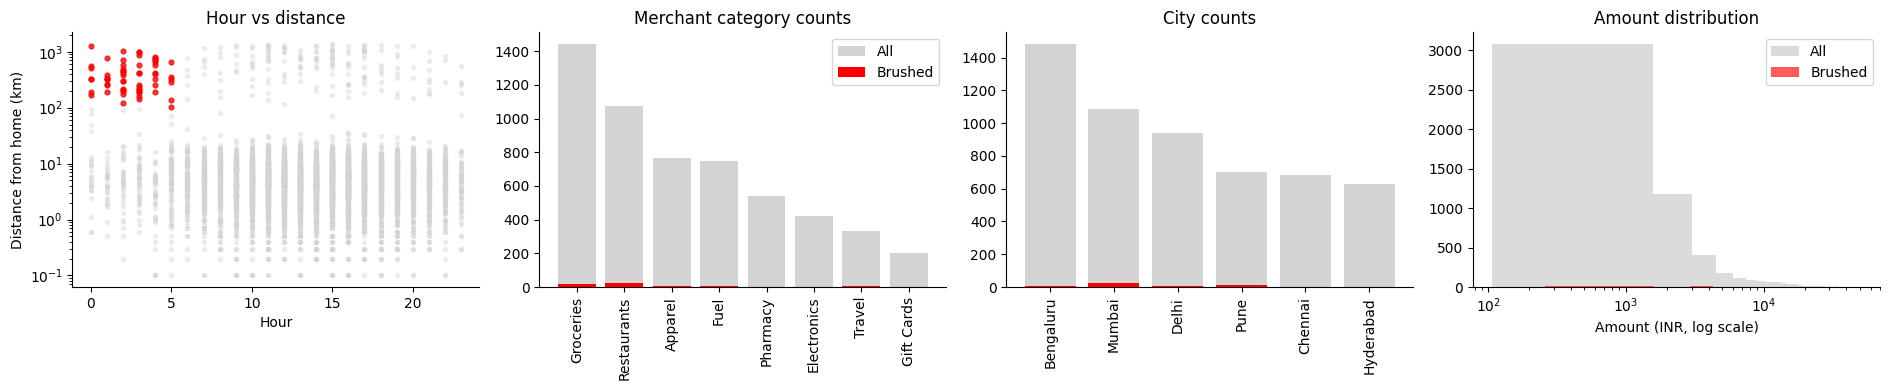

Brushed transactions: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Share of all confirmed fraud captured: 44.17%


In [6]:
# TODO 1: define the brush
brush = (tx["night"] == True) & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2: coordinated views; selected records in red and all records in grey
axes[0].scatter(tx["hour"], tx["distance_from_home_km"].clip(lower=0.1),
                c="lightgrey", s=8, alpha=0.35)
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"].clip(lower=0.1),
                c="red", s=12, alpha=0.75)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs distance")

cat_all = tx["merchant_category"].value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts()
axes[1].bar(cat_all.index, cat_all.values, color="lightgrey", label="All")
axes[1].bar(cat_brush.index, cat_brush.reindex(cat_all.index, fill_value=0).values, color="red", label="Brushed")
axes[1].tick_params(axis="x", rotation=90)
axes[1].set_title("Merchant category counts"); axes[1].legend()

city_all = tx["city"].value_counts()
city_brush = tx.loc[brush, "city"].value_counts()
axes[2].bar(city_all.index, city_all.values, color="lightgrey")
axes[2].bar(city_brush.index, city_brush.reindex(city_all.index, fill_value=0).values, color="red")
axes[2].tick_params(axis="x", rotation=90)
axes[2].set_title("City counts")

axes[3].hist(tx["amount_inr"].clip(lower=0.01), bins=35, color="lightgrey", alpha=0.8, label="All")
axes[3].hist(tx.loc[brush, "amount_inr"].clip(lower=0.01), bins=35, color="red", alpha=0.65, label="Brushed")
axes[3].set_xscale("log"); axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_title("Amount distribution"); axes[3].legend()

plt.tight_layout(); plt.show()

# TODO 3: report size, rates and fraud capture
n_brush = int(brush.sum())
fraud_brush = int(tx.loc[brush, "is_fraud"].sum())
overall_fraud = int(tx["is_fraud"].sum())
rate_brush = fraud_brush / n_brush if n_brush else 0
rate_overall = tx["is_fraud"].mean()
capture = fraud_brush / overall_fraud if overall_fraud else 0
print(f"Brushed transactions: {n_brush:,}")
print(f"Fraud rate inside brush: {rate_brush:.2%}")
print(f"Overall fraud rate: {rate_overall:.2%}")
print(f"Share of all confirmed fraud captured: {capture:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

A high fraud rate means the rule is useful for prioritizing the selected transactions, but the capture share (recall) tells us how much of all confirmed fraud it actually finds. If that share is low, the rule misses many fraud cases and should not be used as the only detector. The linked city and merchant-category views help investigators see where the remaining transactions are distributed and explore additional patterns.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [7]:
# TODO 1: create approximately 1 million rows and time the filter (best of 5)
target_rows = 1_000_000
repeat_factor = int(np.ceil(target_rows / len(tx)))
big = pd.concat([tx] * repeat_factor, ignore_index=True).iloc[:target_rows].copy()

def run_filter():
    return big.loc[(big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)]

times = []
for _ in range(5):
    start = time.perf_counter()
    _ = run_filter()
    times.append(time.perf_counter() - start)
best_s = min(times)

# TODO 2: per-item cost and maximum rows for a 0.1-second response
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big)) if best_s > 0 else float("inf")

# TODO 3: extrapolate to 50 million rows and estimate rows to skip
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0, (1 - 0.1 / t_50m) * 100) if t_50m > 0 else 0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,000,000 rows in 12.2 ms -> 0.0122 us/row -> max 8,221,620 rows in 0.1 s
50M rows -> 0.61 s; must skip 83.6% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
Use aggregation / pre-aggregation (a reduce technique): compute summaries for time or score buckets in advance and let the slider query those smaller summaries. This can keep interaction responsive, but the analyst loses transaction-level detail and may miss rare fraud cases hidden within a bucket.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

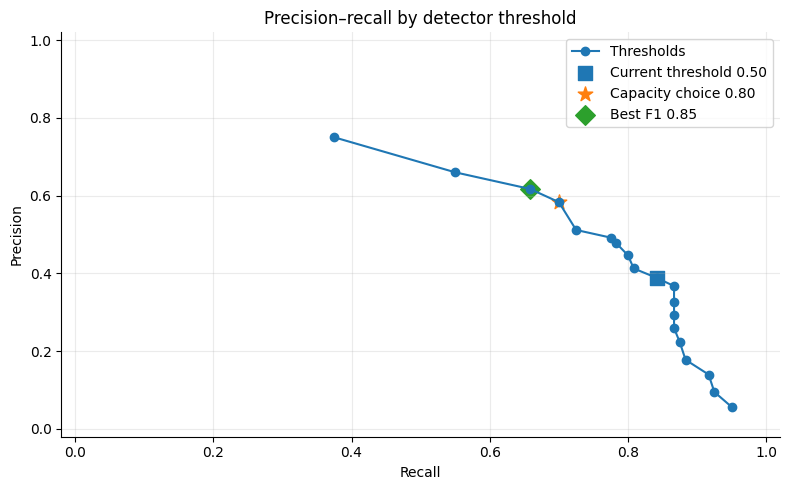

Recommendation: use threshold 0.80 for the 150-alert capacity (alerts=144, precision=58.33%, recall=70.00%); best-F1 threshold is 0.85.


In [8]:
rows = []
# TODO 1: evaluate thresholds from 0.05 to 0.95
y = tx["is_fraud"].astype(int).to_numpy()
scores = tx["detector_score"].to_numpy()
for threshold in np.arange(0.05, 1.00, 0.05):
    pred = scores >= round(float(threshold), 2)
    tp = int(((pred) & (y == 1)).sum())
    fp = int(((pred) & (y == 0)).sum())
    fn = int(((~pred) & (y == 1)).sum())
    alerts = int(pred.sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": round(float(threshold), 2), "alerts": alerts, "TP": tp, "FP": fp, "FN": fn,
                 "precision": precision, "recall": recall, "F1": f1})

pr = pd.DataFrame(rows)

# TODO 2: highest recall under capacity and best F1
feasible = pr[pr["alerts"] <= 150]
capacity_choice = (feasible.sort_values(["recall", "precision", "threshold"],
                                        ascending=[False, False, False]).iloc[0]
                   if len(feasible) else pr.sort_values("alerts").iloc[0])
best_f1 = pr.sort_values(["F1", "recall"], ascending=[False, False]).iloc[0]

# TODO 3: precision-recall curve and mark selected thresholds
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", label="Thresholds")
current = pr.iloc[(pr["threshold"] - 0.5).abs().argmin()]
ax.scatter(current["recall"], current["precision"], s=100, marker="s", label="Current threshold 0.50")
ax.scatter(capacity_choice["recall"], capacity_choice["precision"], s=120, marker="*", label=f"Capacity choice {capacity_choice['threshold']:.2f}")
ax.scatter(best_f1["recall"], best_f1["precision"], s=100, marker="D", label=f"Best F1 {best_f1['threshold']:.2f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Precision–recall by detector threshold")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.25); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: use threshold {capacity_choice['threshold']:.2f} for the 150-alert capacity "
      f"(alerts={int(capacity_choice['alerts'])}, precision={capacity_choice['precision']:.2%}, "
      f"recall={capacity_choice['recall']:.2%}); best-F1 threshold is {best_f1['threshold']:.2f}.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops should make the final decision with evidence from the model, because the threshold has operational consequences: too many alerts overwhelm investigators, while too high a threshold can miss fraud. Visual analytics makes the trade-off between precision, recall, F1 and alert volume visible so the human decision-maker can balance risk, capacity and business priorities. The model informs the decision; it should not make the policy choice alone.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [11]:
# TODO 1: Interactive scatter with details-on-demand
import plotly.express as px

flagged = tx.loc[tx["detector_score"] >= 0.3].copy()

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    hover_data=[
        "txn_id",
        "customer_id",
        "city",
        "merchant_category",
        "detector_score",
        "distance_from_home_km"
    ],
    title="Flagged Transactions: Amount vs Time",
    labels={
        "timestamp": "Transaction Time",
        "amount_inr": "Transaction Amount (INR)",
        "label": "Fraud Label"
    }
)

fig_scatter.update_layout(
    template="plotly_white",
    hovermode="closest"
)

fig_scatter.show()


# TODO 2: Sunburst chart — city to merchant category
fig_sun = px.sunburst(
    tx,
    path=["city", "merchant_category"],
    values="amount_inr",
    color="is_fraud",
    color_continuous_scale="Reds",
    title="Transaction Distribution: City → Merchant Category"
)

fig_sun.update_layout(
    template="plotly_white"
)

fig_sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips require investigators to hover over cases one at a time, so comparing hundreds of flagged transactions is slow and makes patterns difficult to see. The overview heatmap and coordinated linked views solve this by showing distributions and clusters across many records at once, while tooltips remain useful for details-on-demand after a suspicious region or case has been selected.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: confirmed fraud is unusually concentrated in Pune during days 18–20.
Fraud rate inside window: 37.38%
Fraud rate outside window: 1.48%
Chi-square p-value: 1.06482e-136
Counter-example comparison:
Window: 107 transactions; fraud rate 37.38%
Same city, other days: 593 transactions; fraud rate 1.85%
Other cities, same days: 457 transactions; fraud rate 0.44%
Rest: 4,363 transactions; fraud rate 1.54%


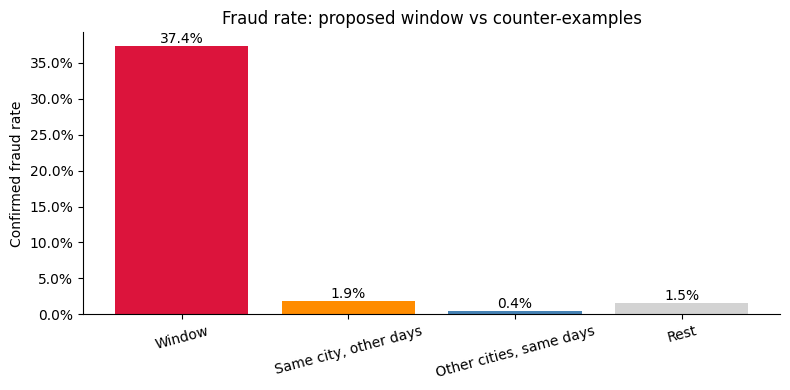

Verdict: The window is statistically associated with elevated fraud; investigate further, but this does not prove a coordinated fraud ring.


In [12]:
from scipy.stats import chi2_contingency

# TODO 1: define a focused city/day window around the strongest city-day fraud cell
fraud_by_city_day = tx.pivot_table(index="city", columns="day", values="is_fraud",
                                   aggfunc="sum", fill_value=0)
top_city, top_day = fraud_by_city_day.stack().idxmax()
day_min = max(int(tx["day"].min()), int(top_day) - 1)
day_max = min(int(tx["day"].max()), int(top_day) + 1)
in_window = (tx["city"].eq(top_city) & tx["day"].between(day_min, day_max))
print(f"Hypothesis: confirmed fraud is unusually concentrated in {top_city} during days {day_min}–{day_max}.")

# TODO 2: rates inside/outside and chi-square test
fraud_table = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, dof, expected = chi2_contingency(fraud_table)
rate_inside = tx.loc[in_window, "is_fraud"].mean() if in_window.any() else 0
rate_outside = tx.loc[~in_window, "is_fraud"].mean() if (~in_window).any() else 0
print(f"Fraud rate inside window: {rate_inside:.2%}")
print(f"Fraud rate outside window: {rate_outside:.2%}")
print(f"Chi-square p-value: {p_value:.6g}")

# TODO 3: counter-example searches
same_city_other_days = tx["city"].eq(top_city) & ~tx["day"].between(day_min, day_max)
other_cities_same_days = ~tx["city"].eq(top_city) & tx["day"].between(day_min, day_max)
rest = ~in_window & ~same_city_other_days & ~other_cities_same_days
groups = {
    "Window": in_window,
    "Same city, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Rest": rest
}
group_rates = {name: tx.loc[mask, "is_fraud"].mean() if mask.any() else 0
               for name, mask in groups.items()}
group_counts = {name: int(mask.sum()) for name, mask in groups.items()}
print("Counter-example comparison:")
for name in groups:
    print(f"{name}: {group_counts[name]:,} transactions; fraud rate {group_rates[name]:.2%}")

# TODO 4: compare the four groups visually
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(list(group_rates.keys()), list(group_rates.values()),
              color=["crimson", "darkorange", "steelblue", "lightgrey"])
ax.set_ylabel("Confirmed fraud rate")
ax.set_title("Fraud rate: proposed window vs counter-examples")
ax.tick_params(axis="x", rotation=15)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for bar, name in zip(bars, group_rates):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{group_rates[name]:.1%}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

# TODO 5: evidence-based verdict; association is not proof of a fraud ring
comparison_max = max(group_rates["Same city, other days"], group_rates["Other cities, same days"])
if rate_inside > rate_outside and p_value < 0.05 and rate_inside > comparison_max:
    verdict = "The window is statistically associated with elevated fraud; investigate further, but this does not prove a coordinated fraud ring."
else:
    verdict = "The evidence does not uniquely support a fraud-ring explanation; the counter-examples or statistical test weaken the claim."
print("Verdict:", verdict)

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

The most informative counter-example is whichever comparison has a fraud rate close to or higher than the proposed window. If the same city on other days had similarly high fraud, that would support a persistent city-level risk rather than a time-limited ring. If other cities on the same days had similarly high fraud, that would support a broader time-related event or detector issue rather than a ring confined to one city. Either result would weaken the claim that the selected city-day window uniquely identifies a fraud ring.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month’s transaction overview and city–day heatmap should be used to identify the strongest fraud clusters, while the linked views quantify how much fraud the “night-time, far-from-home” rule actually captures. I recommend using the threshold selected under the 150-alert monthly capacity constraint, and reviewing its precision and recall alongside the best-F1 alternative before deployment. Build the coordinated overview and interactive flagged-transaction scatter first: linked highlighting exposes patterns across views, and tooltips then provide details on demand. The 50-million-row timing test should guide engineering toward pre-aggregation or other reduction methods if the 0.1-second interaction budget cannot be met. Finally, add a human feedback loop in which investigators label reviewed alerts and confirmed cases, and those labels are used to evaluate and retrain the detector for the next month.